![Banner](../../../../Images/Banner/07_remote_sensing/09_05_banner_rs_hyperspect.png)


# Dimensionality Reduction and Band Selection

Four hundred bands do not carry four hundred independent pieces of information. Neighbouring bands
are almost perfectly correlated, and most of a scene's spectral variety lives in a handful of
directions. This notebook measures that redundancy, compresses Tanager and Pavia cubes with PCA,
MNF and ICA, denoises a cube by keeping only its signal components, estimates how many components
are really needed with HySime and virtual dimensionality, and picks small band subsets that keep a
classifier almost as accurate as with all bands.


## Overview

### Why reduce dimensions

- **Redundancy**: with 5 nm sampling, adjacent bands correlate above 0.99 over most of the
  spectrum. Storage, computation and many algorithms scale with the number of bands.
- **The Hughes phenomenon**: with a fixed number of training samples, classifier accuracy first
  rises and then falls as features are added, because covariance and decision boundaries become
  poorly estimated in high dimensions.
- **Noise**: a few components hold the signal; the rest is mostly noise. Separating them denoises.
- **Endmembers and detection** (notebooks 09_05_07 and 09_05_08) work in a signal subspace whose
  size must be estimated.

### Feature extraction

- **Principal component analysis (PCA)** rotates the data onto orthogonal axes of decreasing
  variance. It ranks components by variance, not by quality, so a noisy but bright band can
  dominate.
- **Minimum noise fraction (MNF)** (Green et al. 1988) first whitens the noise, using a noise
  covariance estimated from neighbouring pixel differences, and then applies PCA. Components are
  ordered by signal to noise ratio; the eigenvalue minus one is the SNR of each component.
  Inverting with only the leading components gives a denoised cube.
- **Independent component analysis (ICA)** finds statistically independent, non Gaussian
  sources, which sometimes isolate single materials better than PCA.

### Intrinsic dimension

- **HySime** (Bioucas-Dias and Nascimento 2008) estimates the noise by spectral regression and
  keeps the eigenvectors whose signal power exceeds the noise power.
- **Virtual dimensionality (VD)** (Harsanyi, Farrand and Chang) counts the eigenvalues of the
  correlation matrix that are significantly larger than those of the covariance matrix: each such
  pair indicates a distinct signal source.

### Band selection

Feature extraction mixes all bands into new variables; **band selection** keeps a subset of the
original bands, which stays physically interpretable and can guide the design of cheaper sensors.
Unsupervised criteria use variance or redundancy; supervised criteria use class labels (mutual
information, ANOVA F, random forest importance). A minimum spectral separation avoids picking
neighbours that carry the same information.


## Dimensionality Reduction with GeoLattice

`hs.pca`, `hs.mnf` and `hs.ica` return a scores cube `(component, y, x)` and a fitted transform
whose `components`, `eigenvalues` and `explained_ratio` describe the rotation; `transform` and
`inverse_transform` apply it to other cubes. `hs.mnf_denoise`, `hs.hysime`,
`hs.virtual_dimensionality` and `hs.select_bands` complete the toolbox.

### Learning objectives

1. Quantify band to band correlation in a hyperspectral cube.
2. Compute PCA and MNF, interpret explained variance, SNR and component images.
3. Denoise a cube with `hs.mnf_denoise` and measure the effect.
4. Estimate the intrinsic dimension with HySime and virtual dimensionality.
5. Select informative bands, with and without labels, and compare their classification accuracy
   with all bands and with PCA and MNF features.

### Data

| Dataset | Use |
|---|---|
| Tanager urban scene (Portland), 300 by 300 pixel window | Correlation, PCA, MNF, ICA, denoising, intrinsic dimension |
| Pavia Centre (ROSIS, 102 bands) with its 9 class ground truth (`Pavia/Pavia_gt.mat`) | Intrinsic dimension, band selection and classification |

### Contents

- Setup
- How redundant are the bands?
- Principal component analysis
- Minimum noise fraction
- Denoising with MNF
- Independent components
- How many components?
- Band selection and classification
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import scipy.io  # read the Pavia ground truth (.mat)
from sklearn.ensemble import RandomForestClassifier  # classifier for the band selection test
from sklearn.metrics import accuracy_score, cohen_kappa_score  # accuracy measures
from geolattice.rsense.dl.hyperspectral import block_split  # spatially blocked train/test split

GeoLattice 0.3.43


## How redundant are the bands?


(350, 300, 300)
adjacent band correlation: median 0.9994, minimum 0.5683 at 1337 nm


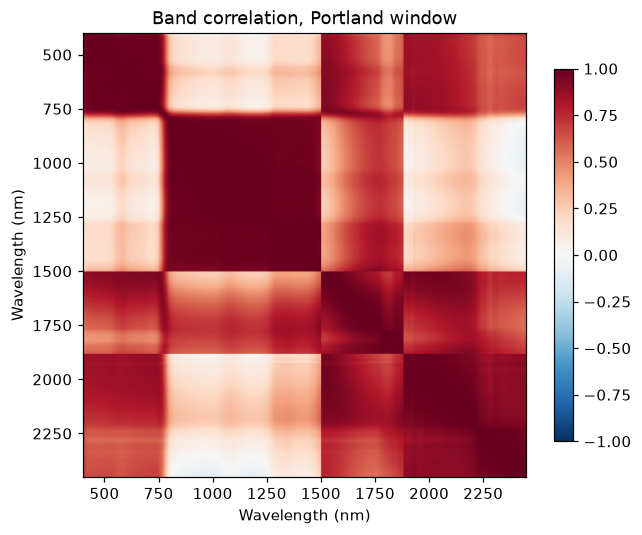

In [2]:
urban = hs.read_tanager(tanager_file("urban"), window=(slice(319, 619), slice(285, 585)))  # Portland, 9 x 9 km
urban = hs.drop_bad_bands(urban)  # remove water vapour windows and noisy ends
print(urban.shape)
X = urban.values.reshape(urban.sizes["band"], -1).T  # (pixels, bands)
X = X[np.all(np.isfinite(X), axis=1)]  # valid pixels
C = np.corrcoef(X, rowvar=False)  # band to band correlation matrix
wl = hs.wavelengths(urban)
neighbour = np.diag(C, 1)  # correlation of each band with the next
print(f"adjacent band correlation: median {np.median(neighbour):.4f}, minimum {neighbour.min():.4f} at {wl[np.argmin(neighbour)]:.0f} nm")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1, extent=[wl[0], wl[-1], wl[-1], wl[0]])
ax.set(xlabel="Wavelength (nm)", ylabel="Wavelength (nm)", title="Band correlation, Portland window")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

The correlation matrix is made of large blocks: the visible, the NIR plateau and the SWIR each
behave almost as one variable, and adjacent bands correlate above 0.99 nearly everywhere. The
weakest links between neighbours are next to the removed absorption windows.


## Principal component analysis


explained variance of PC1 to PC5: [0.6667 0.2845 0.0379 0.0064 0.0013]
components for 99% and 99.9%: 4 12


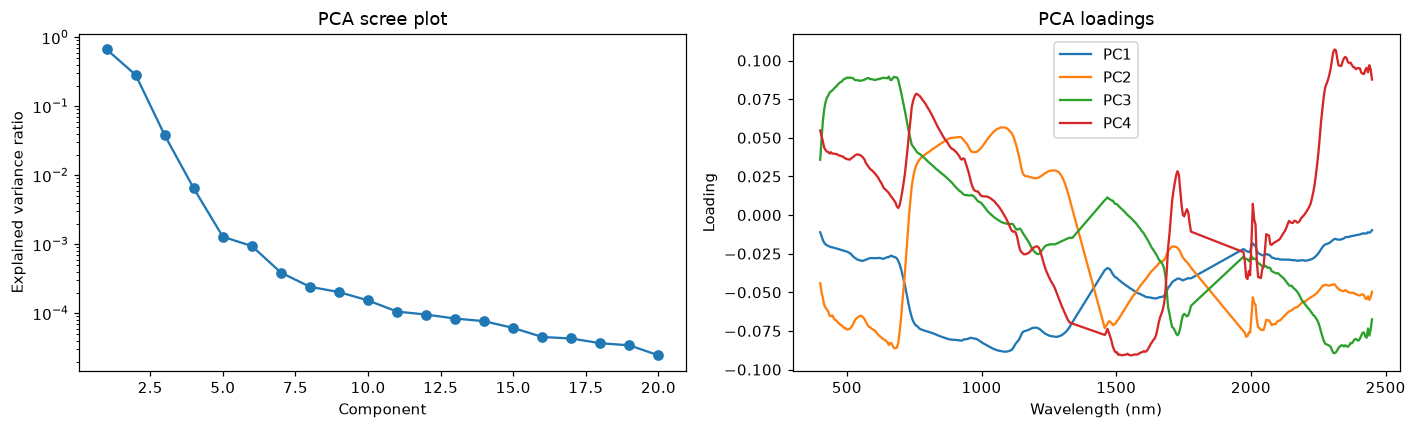

In [3]:
pc, pca_t = hs.pca(urban, 20)  # first 20 principal components
cum = np.cumsum(pca_t.explained_ratio)  # cumulative explained variance
print("explained variance of PC1 to PC5:", np.round(pca_t.explained_ratio[:5], 4))
print("components for 99% and 99.9%:", int(np.searchsorted(cum, 0.99) + 1), int(np.searchsorted(cum, 0.999) + 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogy(np.arange(1, 21), pca_t.explained_ratio[:20], "o-")
axes[0].set(xlabel="Component", ylabel="Explained variance ratio", title="PCA scree plot")
for k in range(4):
    axes[1].plot(wl, pca_t.components[k], label=f"PC{k + 1}")
axes[1].set(xlabel="Wavelength (nm)", ylabel="Loading", title="PCA loadings"); axes[1].legend()
plt.tight_layout()
plt.show()

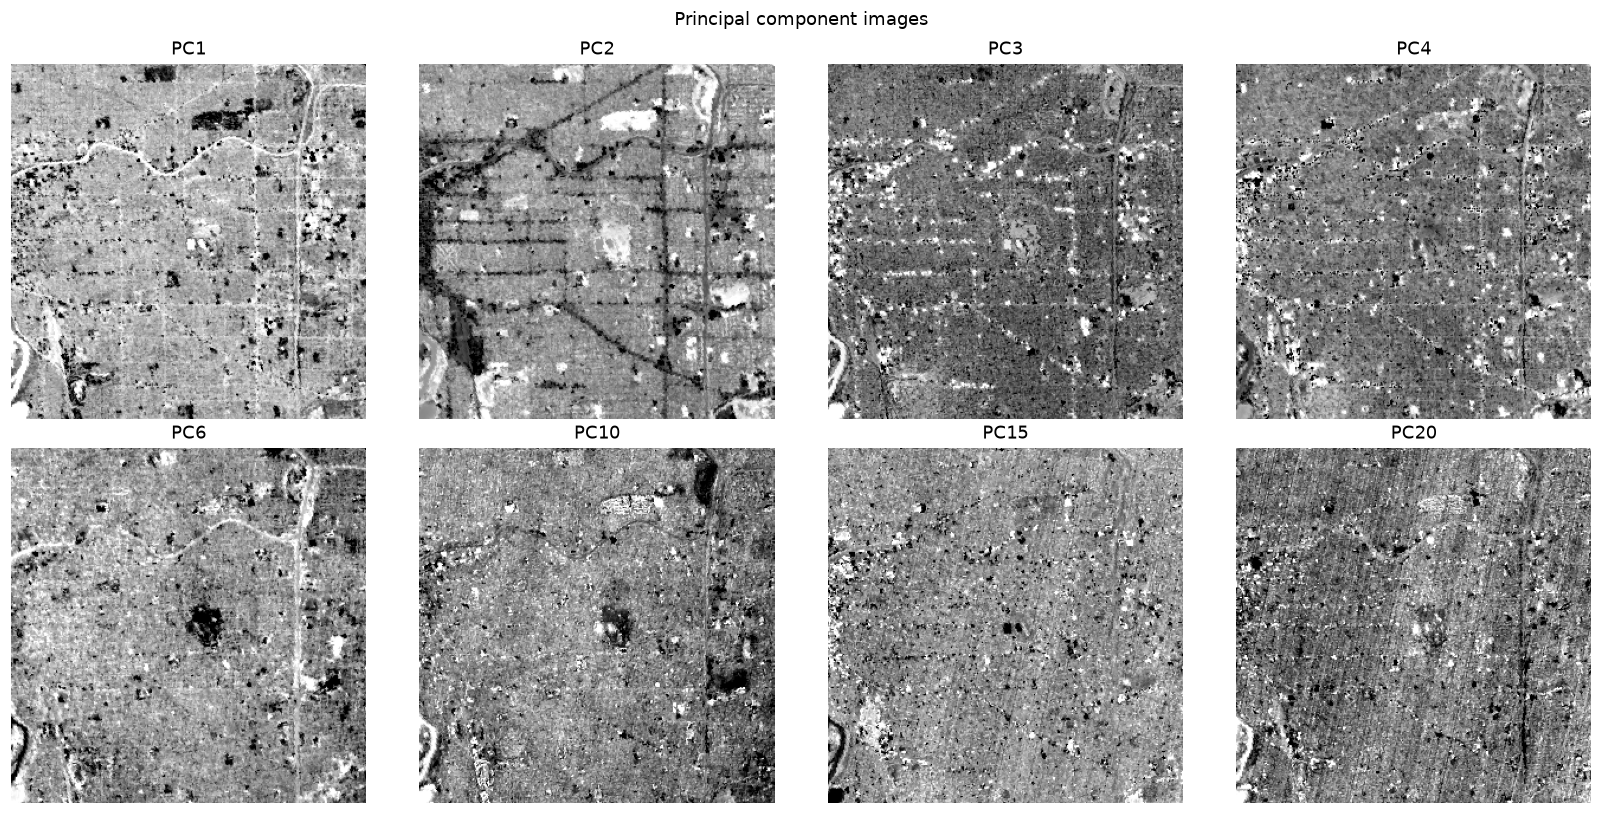

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for k, ax in enumerate(axes.ravel()):
    comp = [0, 1, 2, 3, 5, 9, 14, 19][k]  # components to show
    ax.imshow(pc.isel(component=comp), cmap="gray", vmin=np.nanpercentile(pc.isel(component=comp), 2),
              vmax=np.nanpercentile(pc.isel(component=comp), 98))
    ax.set_title(f"PC{comp + 1}"); ax.axis("off")
plt.suptitle("Principal component images")
plt.tight_layout()
plt.show()

The first component is overall brightness (its loadings have one sign everywhere) and the second
contrasts visible and NIR, which separates vegetation from built surfaces. Together the first few
components hold more than 99 percent of the variance. Higher components carry less and less
structure and more speckle and striping, but because PCA ranks by variance, real but faint
features and noise are mixed in the same components.


## Minimum noise fraction

`hs.mnf` estimates the noise covariance from neighbouring pixel differences, whitens it, and
orders the components by SNR.


SNR of MNF1 to MNF5: [726.9 126.3  61.3  17.   16. ] | components with SNR > 1: 46


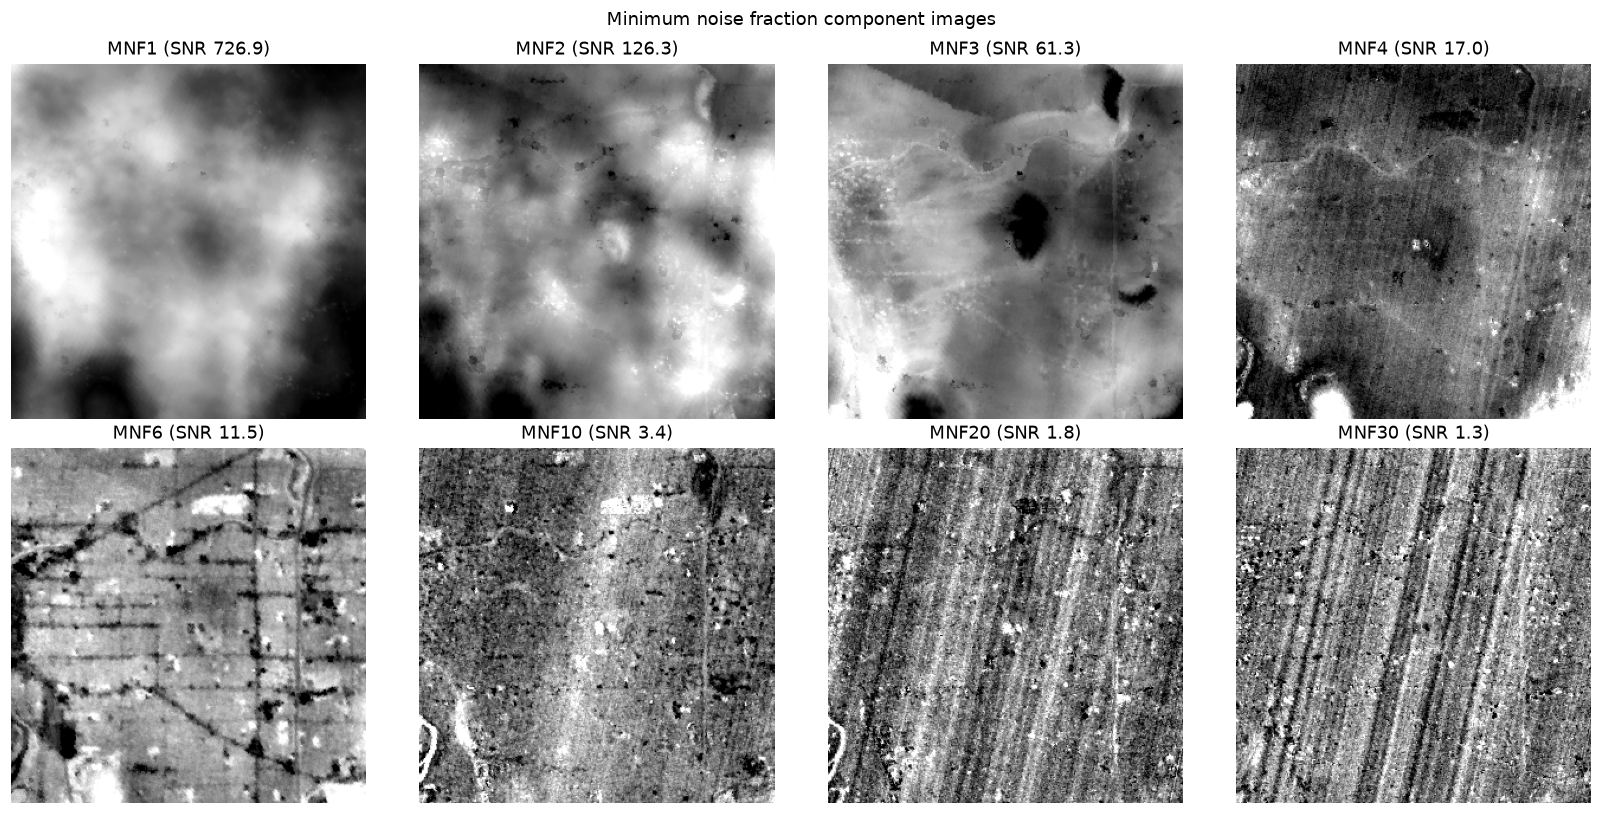

In [5]:
mn, mnf_t = hs.mnf(urban, 30)  # first 30 MNF components
snr = mnf_t.eigenvalues - 1  # SNR of each component
print("SNR of MNF1 to MNF5:", np.round(snr[:5], 1), "| components with SNR > 1:", int((snr > 1).sum()))
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for k, ax in enumerate(axes.ravel()):
    comp = [0, 1, 2, 3, 5, 9, 19, 29][k]
    img = mn.isel(component=comp)
    ax.imshow(img, cmap="gray", vmin=np.nanpercentile(img, 2), vmax=np.nanpercentile(img, 98))
    ax.set_title(f"MNF{comp + 1} (SNR {snr[comp]:.1f})"); ax.axis("off")
plt.suptitle("Minimum noise fraction component images")
plt.tight_layout()
plt.show()

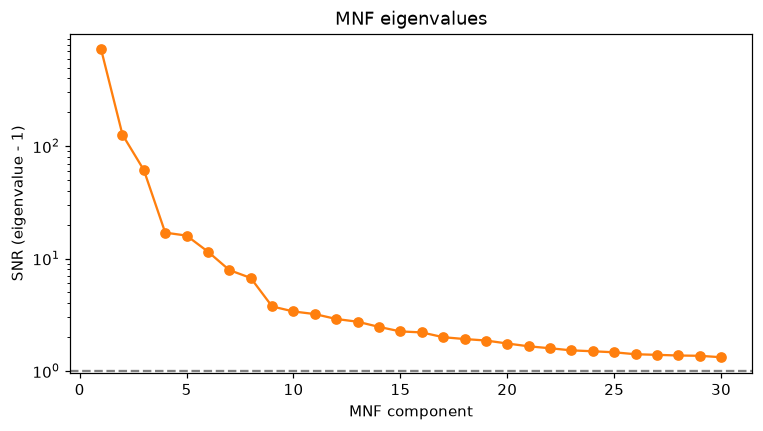

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(np.arange(1, 31), np.clip(snr[:30], 1e-3, None), "o-", color="C1")
ax.axhline(1, color="0.5", ls="--")
ax.set(xlabel="MNF component", ylabel="SNR (eigenvalue - 1)", title="MNF eigenvalues")
plt.show()

MNF components are ordered by SNR rather than by variance, and the result here is instructive. The
first three components are smooth, large scale patterns with very high SNR: the shift difference
noise model sees almost no pixel to pixel change in them, so they look noise free, whatever their
origin (residual atmospheric gradients or smooth land cover trends). The street grid and the parks
appear from MNF4 on, and the late components show diagonal striping and speckle. The catch is that
the shift difference method estimated "noise" from neighbouring pixels, and in a city most of the
difference between neighbouring 30 m pixels is real texture. MNF then rates much of the urban detail
as noise. The next section shows the consequence.


## Denoising with MNF

`hs.mnf_denoise(cube, k)` transforms to MNF space, keeps the first `k` components and transforms
back. It is run with both noise models: the default shift difference and the spectral `residual`
model (`noise="residual"`), which estimates noise from each band's spectral neighbours and is not
fooled by spatial texture. Noise is measured before and after with the residual method from
notebook 09_05_02, and the reconstruction error shows how much real signal each version removes.


,median noise before,median noise after,RMS change to the cube
MNF denoising (20 components),,,
shift noise model,0.00095,0.00013,0.02038
residual noise model,0.00095,0.00011,0.00124


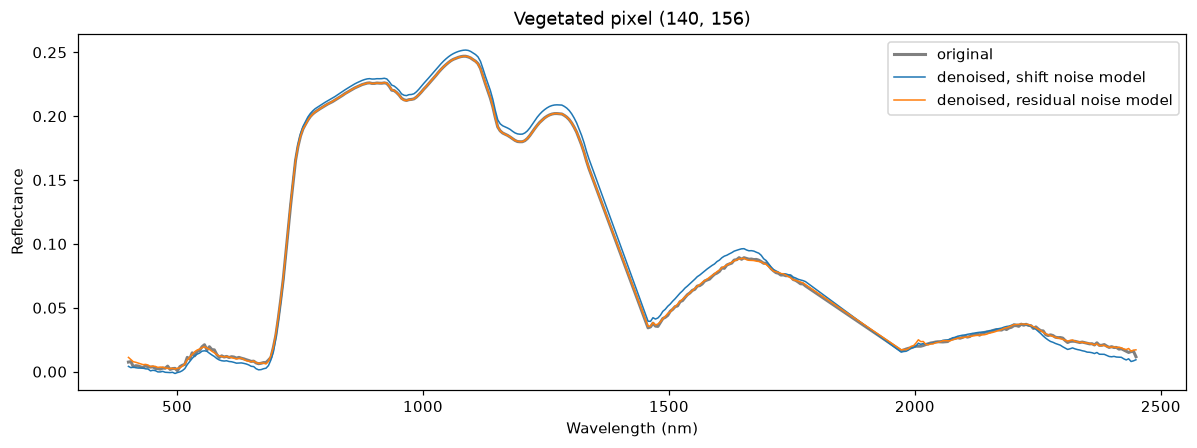

In [7]:
n0 = hs.estimate_noise(urban, method="residual")  # per band noise before
versions = {"shift noise model": hs.mnf_denoise(urban, 20),  # default noise model
            "residual noise model": hs.mnf_denoise(urban, 20, noise="residual")}
rows = []
for name, den in versions.items():
    rows.append({"MNF denoising (20 components)": name,
                 "median noise before": np.median(n0),
                 "median noise after": np.median(hs.estimate_noise(den, method="residual")),
                 "RMS change to the cube": float(np.sqrt(np.nanmean((den.values - urban.values) ** 2)))})
display(pd.DataFrame(rows).set_index("MNF denoising (20 components)").round(5))

G, N = hs.band_at(urban, 560).values, hs.band_at(urban, 860).values  # pick a vegetated pixel
r, c = np.unravel_index(np.nanargmax((N - G) / (N + G)), N.shape)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(wl, urban.values[:, r, c], lw=2, color="0.5", label="original")
for name, den in versions.items():
    ax.plot(wl, den.values[:, r, c], lw=1, label=f"denoised, {name}")
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title=f"Vegetated pixel ({r}, {c})"); ax.legend()
plt.show()

Both versions lower the band to band noise, but only the residual model keeps the signal. With the
shift difference model the cube changes by about 0.02 in reflectance on average, far more than the
noise itself (about 0.001): real urban detail rated as "noise" has been thrown away. Even
this vegetated pixel, an easy case, is shifted away from the original in the NIR and SWIR, and
darker or mixed pixels change much more. With the residual model the change is about the size of
the noise, and the denoised spectrum follows the original without its jitter. MNF is only as good as
its noise estimate: the classic shift difference model suits smooth scenes, while textured scenes
(cities, mixed agriculture) need a spectral noise model. The choice of `k` matters too: keep
somewhat more components than the intrinsic dimension estimated below, or rare materials are lost.


## Independent components


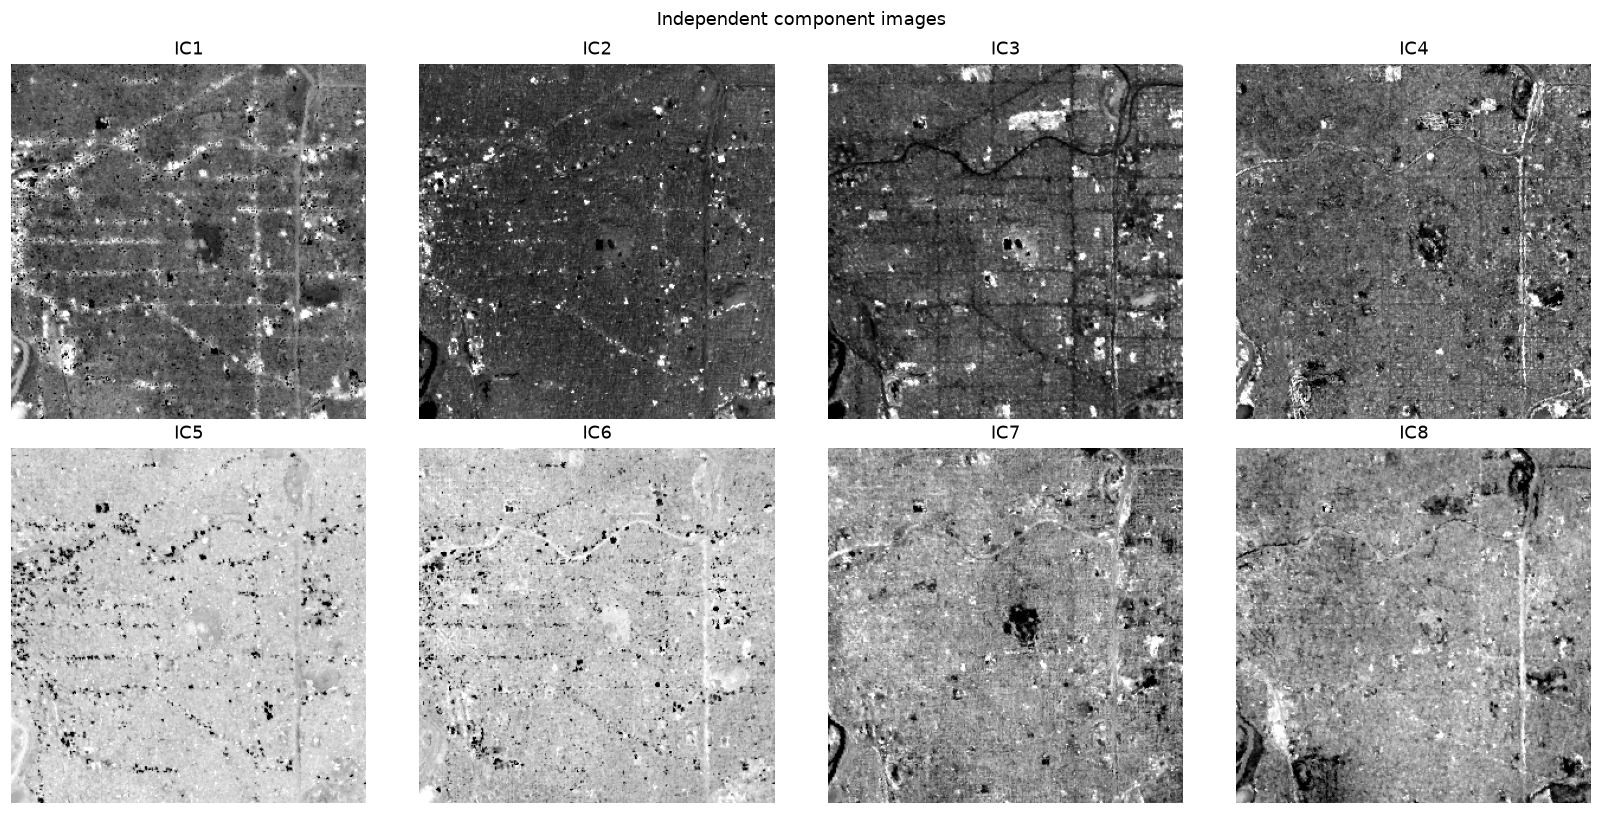

In [8]:
ic, ica_model = hs.ica(urban, 8, sample=40_000)  # 8 independent components
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for k, ax in enumerate(axes.ravel()):
    img = ic.isel(component=k)
    ax.imshow(img, cmap="gray", vmin=np.nanpercentile(img, 1), vmax=np.nanpercentile(img, 99))
    ax.set_title(f"IC{k + 1}"); ax.axis("off")
plt.suptitle("Independent component images")
plt.tight_layout()
plt.show()

ICA components have no natural order. Some of them pick out a single kind of surface (water,
vegetation, particular roofs) more cleanly than any PCA component, because ICA looks for sparse,
non Gaussian sources rather than for directions of maximum variance. They are useful features for
classification and for finding rare targets.


## How many components?

The Pavia Centre cube and its ground truth are loaded here for this and the next section. The 9
classes follow the dataset documentation.


In [9]:
arr = np.load(DATA / "Pavia/pavia.npy")  # (1096, 715, 102)
pavia = hs.as_cube(arr.transpose(2, 0, 1).astype("float32") / 10000, np.linspace(430, 860, arr.shape[2]))
gt = scipy.io.loadmat(DATA / "Pavia/Pavia_gt.mat")["pavia_gt"]  # 0 = unlabelled
NAMES = ["water", "trees", "meadows", "self-blocking bricks", "bare soil", "asphalt", "bitumen", "tiles", "shadows"]
print(pavia.shape, "| labelled pixels:", int((gt > 0).sum()))
pd.Series(np.bincount(gt.ravel())[1:], index=NAMES, name="pixels").to_frame().T

(102, 1096, 715) | labelled pixels: 148152


,water,trees,meadows,self-blocking bricks,bare soil,asphalt,bitumen,tiles,shadows
pixels,65971,7598,3090,2685,6584,9248,7287,42826,2863


In [10]:
rows = []
for name, cube in [("Tanager Portland", urban), ("Pavia Centre", pavia)]:
    hy = hs.hysime(cube, sample=50_000)  # signal subspace by HySime
    _, t = hs.pca(cube, 30, sample=50_000)
    rows.append({"cube": name, "bands": cube.sizes["band"], "HySime k": hy["k"],
                 "VD (alpha 1e-3)": hs.virtual_dimensionality(cube, sample=50_000),
                 "PCA 99%": int(np.searchsorted(np.cumsum(t.explained_ratio), 0.99) + 1),
                 "PCA 99.9%": int(np.searchsorted(np.cumsum(t.explained_ratio), 0.999) + 1)})
pd.DataFrame(rows)

,cube,bands,HySime k,VD (alpha 1e-3),PCA 99%,PCA 99.9%
0,Tanager Portland,350,29,29,4,12
1,Pavia Centre,102,59,10,3,13


The estimates disagree, and that is typical. Variance thresholds count how many components describe
the data's spread, which says little about how many distinct materials there are. HySime and VD
are statistical tests whose answer depends on the noise model and on the number of pixels; with
tens of thousands of pixels they find many components significant. Treat them as ranges, not exact
answers: here, a few to a few tens of components describe each scene. Notebook 09_05_07 uses such
an estimate to choose the number of endmembers.


## Band selection and classification

How much is lost by keeping only ten bands? A random forest is trained on Pavia with all 102 bands,
with ten bands chosen in four ways, and with the first ten PCA and MNF components. Training and test
pixels come from different 32 by 32 pixel blocks (`block_split`), so neighbouring pixels never sit
on both sides; a random pixel split would inflate the accuracy.


In [11]:
train, test = block_split(gt, block=32, test_fraction=0.4, seed=0)  # spatially separate pixel sets
rng = np.random.default_rng(0)
tr_idx = rng.choice(np.flatnonzero(train.ravel()), 6000, replace=False)  # 6000 training pixels
te_idx = np.flatnonzero(test.ravel())  # all test pixels
Xall = pavia.values.reshape(pavia.sizes["band"], -1).T  # (pixels, bands)
y = gt.ravel()
print("train pixels", len(tr_idx), "| test pixels", len(te_idx), "| test classes", np.unique(y[te_idx]).size)

Xtr = pd.DataFrame(Xall[tr_idx], columns=np.round(hs.wavelengths(pavia), 1))  # labelled training spectra
selections = {
    "variance": hs.select_bands(pavia, n=10, method="variance"),
    "decorrelate": hs.select_bands(pavia, n=10, method="decorrelate"),
    "mutual information": hs.select_bands(Xtr, y[tr_idx], n=10, method="mutual_info", min_separation_nm=15),
    "random forest importance": hs.select_bands(Xtr, y[tr_idx], n=10, method="rf", min_separation_nm=15),
}
pd.DataFrame({k: v["wavelength"].round(0).to_numpy() for k, v in selections.items()})

train pixels 6000 | test pixels 56425 | test classes 9


,variance,decorrelate,mutual information,random forest importance
0,813.0,813.0,860.0,783.0
1,809.0,485.0,843.0,860.0
2,800.0,728.0,809.0,843.0
3,805.0,430.0,826.0,809.0
4,817.0,439.0,783.0,715.0
5,796.0,605.0,711.0,698.0
6,822.0,745.0,766.0,826.0
7,830.0,434.0,728.0,532.0
8,826.0,447.0,694.0,741.0
9,775.0,707.0,651.0,766.0


In [12]:
pc_p, _ = hs.pca(pavia, 10)  # 10 principal components
mnf_p, _ = hs.mnf(pavia, 10)  # 10 MNF components
features = {"all 102 bands": Xall}
features.update({f"10 bands: {k}": Xall[:, v["band"].to_numpy()] for k, v in selections.items()})
features["10 PCA components"] = pc_p.values.reshape(10, -1).T
features["10 MNF components"] = mnf_p.values.reshape(10, -1).T

rows = []
for name, F in features.items():
    rf = RandomForestClassifier(300, n_jobs=-1, random_state=0).fit(F[tr_idx], y[tr_idx])  # train
    pred = rf.predict(F[te_idx])  # predict the held-out blocks
    rows.append({"features": name, "overall accuracy": accuracy_score(y[te_idx], pred),
                 "kappa": cohen_kappa_score(y[te_idx], pred)})
res = pd.DataFrame(rows).set_index("features").round(3)
res

,overall accuracy,kappa
features,,
all 102 bands,0.955,0.940
10 bands: variance,0.801,0.729
10 bands: decorrelate,0.946,0.927
10 bands: mutual information,0.930,0.906
10 bands: random forest importance,0.951,0.935
10 PCA components,0.962,0.950
10 MNF components,0.967,0.956


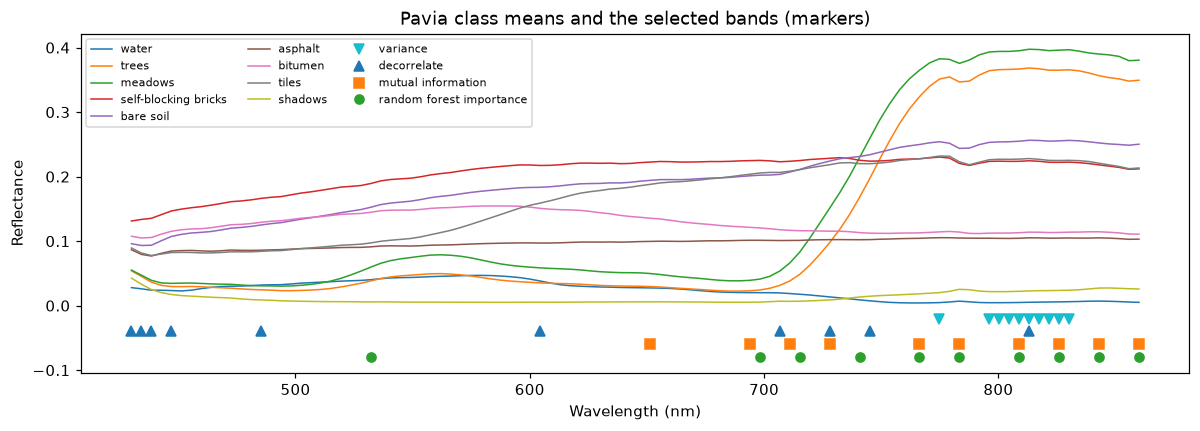

In [13]:
fig, ax = plt.subplots(figsize=(13, 4))
mean_by_class = [np.nanmean(Xall[y == k], axis=0) for k in range(1, 10)]  # class mean spectra
for k, s in enumerate(mean_by_class):
    ax.plot(hs.wavelengths(pavia), s, lw=1, label=NAMES[k])
for (name, sel), m in zip(selections.items(), ["v", "^", "s", "o"]):
    ax.plot(sel["wavelength"], np.full(len(sel), -0.02 - 0.02 * list(selections).index(name)), m, ms=6, label=name)
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Pavia class means and the selected bands (markers)")
ax.legend(fontsize=7, ncol=3)
plt.show()

Ten PCA or MNF components classify the held-out blocks slightly better than all 102 bands (overall
accuracy about 0.96 to 0.97 against 0.955), and ten bands chosen by decorrelation or random forest
importance come within one point of all bands. Mutual information is a little lower because it picks
mostly correlated bands on the red edge and NIR plateau. The variance criterion fails (about 0.80):
all ten of its bands sit side by side on the bright NIR plateau, where classes spread most but carry
the same information. Decorrelation spreads its picks across the blue, the red and the red edge, and
the random forest adds a green band, which is why both work well. With this many training pixels the Hughes effect is
small for a random forest; it matters more for parametric classifiers and small training sets.


## Summary and exercises

**Key points**

- Adjacent hyperspectral bands are almost perfectly correlated; the spectrum behaves like a few
  blocks of variables.
- PCA concentrates variance in a few components but ranks noise and signal together; MNF ranks by
  SNR, but only as well as its noise model allows.
- In textured scenes the shift difference noise model treats real detail as noise; MNF denoising
  with the spectral residual model removes band to band noise and keeps the signal.
- Intrinsic dimension estimates (HySime, VD, variance thresholds) disagree; use them as ranges.
- A few bands or components retain nearly all the class information; supervised selection with a
  spectral separation gives interpretable subsets.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `drop_bad_bands`, `as_cube`,
`pca`, `mnf`, `mnf_denoise`, `ica`, `estimate_noise`, `hysime`, `virtual_dimensionality`,
`select_bands`; `geolattice.rsense.dl.hyperspectral.block_split`.

**Exercises**

1. Repeat the PCA scree plot on the snow and ice scene. How many components reach 99 percent?
2. Denoise with 5, 10, 20 and 40 MNF components and plot the residual noise against `k`.
3. Change `block_split(block=...)` to 8 and 64 pixels. How does the measured accuracy change, and
   why?
4. Train with only 300 pixels. Does the gap between all bands and ten bands grow?
5. Use `select_bands(..., method="anova")` and compare its bands with mutual information.
